In [1]:
import os
import logging
logging.getLogger('tensorflow').setLevel(logging.ERROR)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.callbacks import EarlyStopping

print("✓ All libraries imported successfully")

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

✓ All libraries imported successfully


In [2]:
import os
dataset_path = 'garbage-classification/Garbage classification/Garbage classification'
contents = os.listdir(dataset_path)
print(f"Contents of Garbage classification: {contents}")
for item in contents:
    item_path = os.path.join(dataset_path, item)
    if os.path.isdir(item_path):
        sub_contents = os.listdir(item_path)
        print(f"  {item} is a folder with {len(sub_contents)} images: {sub_contents[:3]}")
    else:
        print(f"  {item} is a file")

Contents of Garbage classification: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
  cardboard is a folder with 403 images: ['cardboard1.jpg', 'cardboard10.jpg', 'cardboard100.jpg']
  glass is a folder with 501 images: ['glass1.jpg', 'glass10.jpg', 'glass100.jpg']
  metal is a folder with 410 images: ['metal1.jpg', 'metal10.jpg', 'metal100.jpg']
  paper is a folder with 594 images: ['paper1.jpg', 'paper10.jpg', 'paper100.jpg']
  plastic is a folder with 482 images: ['plastic1.jpg', 'plastic10.jpg', 'plastic100.jpg']
  trash is a folder with 137 images: ['trash1.jpg', 'trash10.jpg', 'trash100.jpg']


In [14]:
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
train_datagen_eff = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.25,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen_eff = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

img_size = (224, 224)
batch_size = 32

train_generator = train_datagen_eff.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical'
    
)

validation_generator = train_datagen_eff.flow_from_directory(
    dataset_path,
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical'
)

num_classes = len(train_generator.class_indices)
print(f"✓ Classes: {train_generator.class_indices}")
print(f"✓ Total classes: {num_classes}")

Found 2527 images belonging to 6 classes.
Found 2527 images belonging to 6 classes.
✓ Classes: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
✓ Total classes: 6


In [15]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

In [25]:
base_model_eff = EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model_eff.trainable = False

In [26]:
eff_model = models.Sequential([
    base_model_eff,
    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation='softmax')
])

In [27]:
eff_model.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✓ EfficientNetB0 model compiled")
print(f"✓ Total parameters: {eff_model.count_params():,}")

✓ EfficientNetB0 model compiled
✓ Total parameters: 4,400,745


In [28]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("🚀 Training EfficientNetB0 (head only)...")

history_eff = eff_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=15,
    callbacks=[early_stop]
)

print("✓ EfficientNetB0 head training completed!")

🚀 Training EfficientNetB0 (head only)...
Epoch 1/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 67s 761ms/step - accuracy: 0.3390 - loss: 1.9442 - val_accuracy: 0.7507 - val_loss: 1.0253
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 61s 757ms/step - accuracy: 0.5932 - loss: 1.0786 - val_accuracy: 0.8085 - val_loss: 0.7310
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 62s 773ms/step - accuracy: 0.6687 - loss: 0.9004 - val_accuracy: 0.8366 - val_loss: 0.5652
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 734ms/step - accuracy: 0.7268 - loss: 0.7925 - val_accuracy: 0.8560 - val_loss: 0.4632
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 60s 750ms/step - accuracy: 0.7310 - loss: 0.7358 - val_accuracy: 0.8583 - val_loss: 0.4211
Epoch 6/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 733ms/step - accuracy: 0.7670 - loss: 0.6550 - val_accuracy: 0.8769 - val_loss: 0.3764
Epoch 7/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 57s 704ms/step - accuracy: 0.7762 - loss: 0.6353 - val_accuracy: 0.8896 - val_loss: 0.3478
Epoch 8/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 59s 730ms/step - a

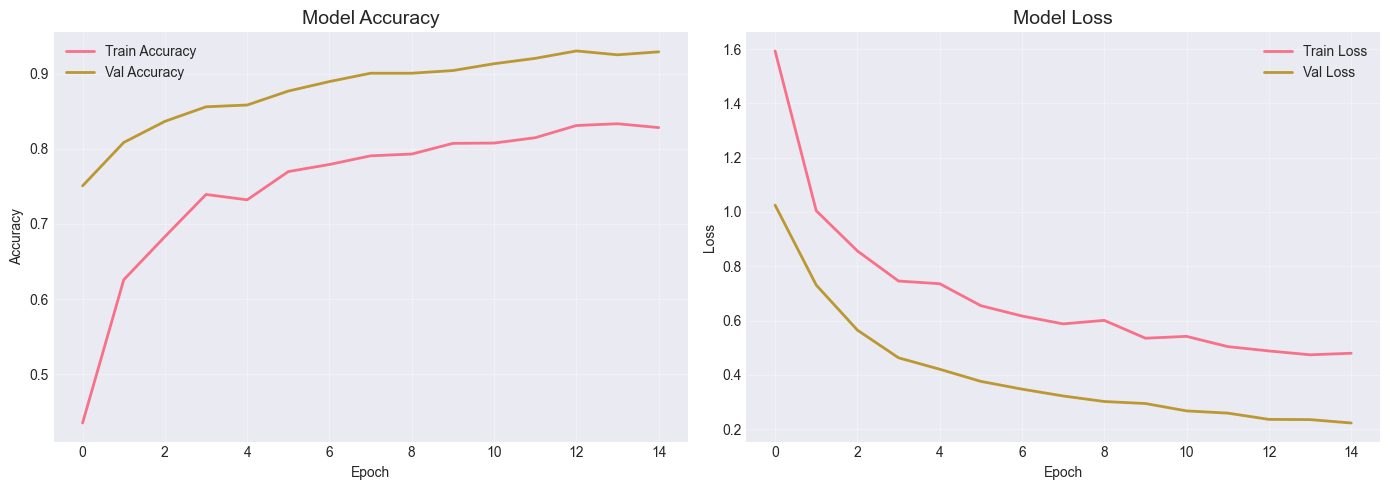


📊 Final Results:
   Train Accuracy: 0.8283
   Val Accuracy: 0.9292


In [31]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_eff.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history_eff.history['val_accuracy'], label='Val Accuracy', linewidth=2)
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_eff.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history_eff.history['val_loss'], label='Val Loss', linewidth=2)
plt.title('Model Loss', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# แสดงผล accuracy สุดท้าย
print(f"\n📊 Final Results:")
print(f"   Train Accuracy: {history_eff.history['accuracy'][-1]:.4f}") 
print(f"   Val Accuracy: {history_eff.history['val_accuracy'][-1]:.4f}") 

In [29]:
eff_model.save("models/efficientnetb0_head_only.keras")
print("✅ EfficientNetB0 model saved")

✅ EfficientNetB0 model saved
